# Commuting zones: a hypothesis-driven specification search

This case asks which recorded characteristics help predict life expectancy for
men in the bottom income quartile in states absent from model fitting. It also
shows how an analyst can use mboostrs one test at a time: state a hypothesis,
choose an action, read its evidence, and decide what to test next. The calls below are chosen by the analyst and run through `SearchSession`; no language model is run.
A human or coding agent can use these public operations to choose the next
diagnostic or comparison. The existing `modeler_loop` LLM callback instead
runs a fixed action sequence.

The Health Inequality Project reports one row per commuting zone, a group of
counties linked by commuting. `le_raceadj_q1_M` estimates expected age at death
for a 40-year-old man in the bottom income quartile, adjusted for the area's
racial composition, in years. The study and variable definitions come from
{cite:t}`chetty2016inequality` and its
[commuting-zone codebook](https://www.healthinequality.org/dl/health_ineq_online_table_10_readme.pdf).
The five substantive columns below are a prespecified teaching subset of the
full 39-characteristic frame. The [larger descriptive study](cz_inequality.ipynb) examines all recorded
characteristics. A separate scripted five-split runner is
`benches/bench_cz_agent_search.py`; it does not use this agent-directed session.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | prediction for a commuting zone in a state absent from fitting |
| **Response** | race-adjusted expected age at death at 40 for bottom-quartile men |
| **Estimand** | mean squared prediction error on zones in held-out states, in years² |
| **Sampling unit** | one commuting zone; zones within a state may be dependent |
| **Split unit** | entire states; one of five groups is kept for final testing,
  five folds of the remaining states choose specifications and `mstop` |
| **Uncertainty** | paired fold standard errors describe exploratory training
  comparisons; one held-out group of nine states supplies the final score |
| **Claim** | prediction and area-level association, not intervention effects |
:::

## Variable roles and questions

We decide what each column means before looking at search scores. Smoking among
bottom-quartile residents is a plausible health-behaviour pathway, though this
area-level measure cannot identify the effect of quitting. Medicare dollars per
enrollee measure spending for a different, older or disabled population; they
could also reflect illness burden, prices or intensity of care. Percent Black
is an area-composition variable, not a biological treatment. It may stand for
structural conditions, including segregation and educational opportunity.
The selected response is already race-adjusted; neither adjustment nor a
predictive spline establishes what the demographic-share term represents.

| Column | Question tested | Evidence against a simple reading |
|---|---|---|
| Current smoking, Q1 | Is the fitted association decreasing, and does a
  decreasing constraint cost held-out accuracy? | A worse constrained fit or
  unstable shape across states |
| Medicare dollars/enrollee | Does this column add predictive information,
  and is its decreasing profile stable? | No added fold performance; a spending
  coefficient cannot be read as a care intervention |
| Percent Black | Is the curved association needed for prediction, or can
  segregation/education substitute for it? | A weak incremental gain, limited
  support, or a changed curve under structural covariates |

These are predictive and diagnostic tests. A causal study would need an
intervention, time zero, confounder assumptions and suitable longitudinal or
quasi-experimental evidence. The answers below cannot supply those inputs.

## Training states and test states

The state assignment uses **state labels only**, before any response-aware scan
or fit. We then select the declared variables and omit rows missing any of
them, separately within each side of the split. The session receives the
training frame only. Test responses first enter at final evaluation.

In [1]:
import altair as alt
import numpy as np
import polars as pl
from IPython.display import display

import mboostrs as mb
from bench_tables import table

alt.renderers.enable("svg")
raw = mb.datasets.hip_cz(output="polars")
response = "le_raceadj_q1_M"
columns = [response, "stateabbrv", "cur_smoke_q1", "reimb_penroll_adj10",
           "cs_frac_black", "cs_race_theil_2000", "cs_educ_ba", "lon", "lat"]
assignment = np.asarray(mb.grouped_folds(
    np.asarray(raw["stateabbrv"].to_list(), dtype=object), B=5, seed=2016))
train = raw.filter(pl.Series(assignment[:, 0] != 0)).select(columns).drop_nulls()
test = raw.filter(pl.Series(assignment[:, 0] == 0)).select(columns).drop_nulls()
print(f"Training: {train.height} zones in {train['stateabbrv'].n_unique()} states")
print(f"Test: {test.height} zones in {test['stateabbrv'].n_unique()} states")

Training: 472 zones in 41 states
Test: 118 zones in 9 states


The test assignment is fixed before any comparison. All remaining diagnostics and candidate
comparisons run on the training states. Grouped folds inside that sample mimic
the task of predicting a state the model has never fitted.

## Session and initial model

`open_search` keeps one family, score, fold design and fit budget for a sequence
of caller-chosen actions. Gaussian fitting targets continuous years; `score="mse"`
compares squared prediction errors in years². `groups="stateabbrv"` holds whole
states out in five folds. The state term fits differences among training states
but predicts an average state on new-state folds. `CostBudget(fits=300)`, a cap of 300 model fits charged to the session, applies
to every action in the session, and the session never receives `test` here.
We begin with linear effects and compare them with smooth alternatives on
the grouped folds.

In [2]:
session = mb.open_search(
    train, response, family=mb.Gaussian(), score="mse",
    groups="stateabbrv", folds=5, seed=4, mstop=100, nu=.3,
    budget=mb.CostBudget(fits=300), locks=("stateabbrv",),
)
observed_types = session.run("classify")
linear = ("bols(cur_smoke_q1) + bols(reimb_penroll_adj10) "
          "+ bols(cs_frac_black) + brandom(stateabbrv)")
session.run("set_spec", rhs=linear)
print("Next available actions:", ", ".join(session.state()["available_actions"]))
print("Initial formula:", session.spec)

Next available actions: classify, column_screen, autospec, pre_scan, transform_candidates, structure_candidates, hypothesis, set_family, set_spec, lock, compare, evaluate, term_report, tune, check_declarations, fit, response_probe, pair_candidates, tree_candidate
Initial formula: bols(cur_smoke_q1) + bols(reimb_penroll_adj10) + bols(cs_frac_black) + brandom(stateabbrv)


## Recorded hypotheses

The three hypotheses enter the session as analyst statements before the
candidate results. Each names evidence that could count against its
simple interpretation. Recording a hypothesis does not change the fit.

In [3]:
questions = [
    ("cur_smoke_q1", "possible health-behaviour pathway",
     "A decreasing smoking profile may predict longer lives at lower prevalence.",
     "The decreasing constraint worsens new-state fold error."),
    ("reimb_penroll_adj10", "spending and illness-burden proxy",
     "Medicare spending may add information beyond smoking and composition.",
     "Omitting it has little cost on new-state folds."),
    ("cs_frac_black", "possible structural proxy, not an intervention",
     "The demographic-share curve may partly reflect segregation or education.",
     "A structural covariate replaces its predictive gain, or support is sparse."),
]
for variable, role, statement, counterevidence in questions:
    session.run("hypothesis", variable=variable, role=role,
                statement=statement, would_count_against=counterevidence)
print(f"Recorded {session.state()['hypothesis_count']} questions before comparison")

Recorded 3 questions before comparison


## Smooth effects: the first comparison

The analysis asks whether three smooth effects improve prediction over the linear
start. Both candidates use the same state folds and 100 boosting iterations.
The table's error change is candidate minus current MSE; negative values favour
the candidate. A change is accepted when its reduction exceeds two paired fold
standard errors. This is a search rule, not a hypothesis test.

In [4]:
smooth = ("bbs(cur_smoke_q1) + bbs(reimb_penroll_adj10) "
          "+ bbs(cs_frac_black) + brandom(stateabbrv)")
smoke_only = linear.replace("bols(cur_smoke_q1)", "bbs(cur_smoke_q1)")
shape_result = session.run("compare", candidates={
    "smooth three": smooth, "smooth smoking only": smoke_only,
})
shape_rows = shape_result.value
display(table(
    pl.DataFrame([{"candidate": r["specification"],
                   "mse": r["out-of-fold risk"], "change": r["change"],
                   "se": r["change se"]} for r in shape_rows]),
    title="Initial shapes on five training-state folds",
    subtitle="MSE and paired changes in years²; lower is better",
    stub="candidate", stubhead="Specification", better={"mse": "min"},
    notes=("Change = candidate MSE − linear MSE. SE uses the five paired fold differences.",
           "Several candidates share these folds, so the table is descriptive search evidence."),
))

/Users/fcela/src/public_github/mboostrs/python/mboostrs/_extrapolation.py:187: ExtrapolationWarning: 4 fold predictions in this call asked 3 learner(s) to predict outside the range they were fitted on. bbs(cur_smoke_q1), covariate cur_smoke_q1: 5 above 0.419753 (worst 0.26 training ranges out); bbs(cs_frac_black), covariate cs_frac_black: 2 above 58.906 (worst 0.12 training ranges out); bbs(reimb_penroll_adj10), covariate reimb_penroll_adj10: 1 above 13094.4 (worst 0.081 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.26 training ranges out that is an assumption, not an estimate. Pass compare_specifications(extrapolation='allow') to accept it, or extrapolation='clip' to hold the effect flat outside the range instead, or extrapolation='error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  with routine_warnings(stacklevel=3, owner=fn.__name__):


GT(_tbl_data=shape: (3, 4)
┌─────────────────────┬──────────┬───────────┬──────────┐
│ candidate           ┆ mse      ┆ change    ┆ se       │
│ ---                 ┆ ---      ┆ ---       ┆ ---      │
│ str                 ┆ f64      ┆ f64       ┆ f64      │
╞═════════════════════╪══════════╪═══════════╪══════════╡
│ current             ┆ 1.169078 ┆ 0.0       ┆ 0.0      │
│ smooth three        ┆ 1.039961 ┆ -0.129117 ┆ 0.043387 │
│ smooth smoking only ┆ 1.168626 ┆ -0.000453 ┆ 0.00516  │
└─────────────────────┴──────────┴───────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10ac345f0>, _boxhead=Boxhead([ColInfo(var='candidate', type=<ColInfoTypeEnum.stub: 2>, column_label='candidate', column_align='left', column_width=None), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='mse', column_align='right', column_width=None), ColInfo(var='change', type=<ColInfoTypeEnum.default: 1>, column_label='change', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x109efb8c0>, _spanners=Spanners([]), _heading=Heading(title='Initial shapes on five training-state folds', subtitle='MSE and paired changes in years²; lower is better', preheader=None), _stubhead='Specification', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x109f1c530>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10a126fc0>, _source_notes=['Change = candidate MSE − linear MSE. SE uses the five paired fold differences.', 'Several candidates share these folds, so the table is descriptive search evidence.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10c26f2c0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10c2ac800>, <great_tables._gt_data.FormatInfo object at 0x10c380a70>, <great_tables._gt_data.FormatInfo object at 0x10c374e30>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10c377a40>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='tabl

The three-smooth candidate reduces fold MSE by
{eval}`round(-shape_rows[1]['change'], 3)` years² (paired SE
{eval}`round(shape_rows[1]['change se'], 3)`), enough for the stated rule.
Smoothing smoking alone reduces it by only
{eval}`round(-shape_rows[2]['change'], 3)` years². The analysis therefore adopts
the complete three-smooth formula and tunes its stopping iteration before asking what its remaining
residuals or effect shapes mean.

In [5]:
chosen_shape = session.run(
    "adopt", comparison_id=shape_result.evidence_id, candidate="smooth three")
tuning = session.run("tune", start=100)
print("Accepted:", chosen_shape.summary["spec"])
print(f"Tuned iterations: {session.mstop}; charged fits: "
      f"{session.state()['budget']['fit_charges']}")

Accepted: bbs(cur_smoke_q1) + bbs(reimb_penroll_adj10) + bbs(cs_frac_black) + brandom(stateabbrv)
Tuned iterations: 114; charged fits: 26


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_extrapolation.py:187: ExtrapolationWarning: 6 fold predictions in this call asked 3 learner(s) to predict outside the range they were fitted on. bbs(cur_smoke_q1), covariate cur_smoke_q1: 5 above 0.419753 (worst 0.26 training ranges out); bbs(cs_frac_black), covariate cs_frac_black: 2 above 58.906 (worst 0.12 training ranges out); bbs(reimb_penroll_adj10), covariate reimb_penroll_adj10: 1 above 13094.4 (worst 0.081 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.26 training ranges out that is an assumption, not an estimate. Pass tune_mstop(extrapolation='allow') to accept it, or extrapolation='clip' to hold the effect flat outside the range instead, or extrapolation='error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  with routine_warnings(stacklevel=3, owner=fn.__name__):


## First prediction

The accepted fit now predicts a new-state zone using the average state effect.
We vary smoking prevalence between two values inside the training range,
keeping spending, composition, segregation, education and location at their
training medians. This is a complete fit–tune–predict path before the longer
investigation below. The change in prediction is an area-level association,
not the effect of making someone quit smoking.

In [6]:
typical = {name: float(train[name].median()) for name in columns
           if name not in (response, "stateabbrv")}
new_zones = pl.DataFrame([
    {**typical, "cur_smoke_q1": smoking, "stateabbrv": "new state"}
    for smoking in (.22, .34)
])
example_predictions = new_zones.select("cur_smoke_q1").with_columns(pl.Series(
    "predicted_years", session.model.predict(new_zones, type="response",
                                                unseen_levels="average"),
))
display(table(
    example_predictions, title="Predictions for two new-state profiles",
    subtitle="Years of expected age at death; other characteristics at training medians",
    stub="cur_smoke_q1", stubhead="Smoking share, Q1",
    labels={"predicted_years": "Predicted years"},
    notes=("The profiles are conditional predictions, not smoking-intervention effects.",),
))

GT(_tbl_data=shape: (2, 2)
┌──────────────┬─────────────────┐
│ cur_smoke_q1 ┆ predicted_years │
│ ---          ┆ ---             │
│ f64          ┆ f64             │
╞══════════════╪═════════════════╡
│ 0.22         ┆ 76.839145       │
│ 0.34         ┆ 76.169303       │
└──────────────┴─────────────────┘, _body=<great_tables._gt_data.Body object at 0x109f1c4a0>, _boxhead=Boxhead([ColInfo(var='cur_smoke_q1', type=<ColInfoTypeEnum.stub: 2>, column_label='cur_smoke_q1', column_align='right', column_width=None), ColInfo(var='predicted_years', type=<ColInfoTypeEnum.default: 1>, column_label='Predicted years', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10c385820>, _spanners=Spanners([]), _heading=Heading(title='Predictions for two new-state profiles', subtitle='Years of expected age at death; other characteristics at training medians', preheader=None), _stubhead='Smoking share, Q1', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10c385dc0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x1098ec470>, _source_notes=['The profiles are conditional predictions, not smoking-intervention effects.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10c3a80e0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10c3a84a0>, <great_tables._gt_data.FormatInfo object at 0x10c374fe0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x110f4b950>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_bottom_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_left_style=OptionsInfo(scss=True, category='

## Smoking and Medicare profiles

The fitted smooths are easier to read over the training range than from two
predictions. Each panel varies one measurement between its fifth and 95th
training percentiles, holding the others at their medians and predicting the
average state. The x-axis uses the source unit: smoking is a fraction;
Medicare reimbursement is dollars per enrollee. A descending curve is an
association in this fitted model, not a causal dose-response.

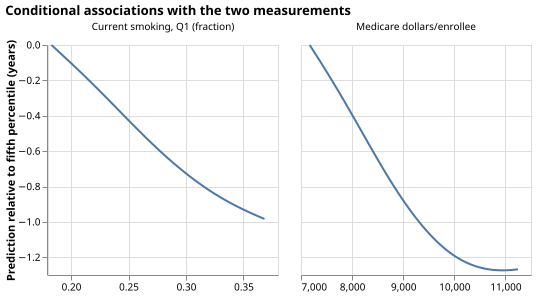

In [7]:
profiles = []
for variable, label in (("cur_smoke_q1", "Current smoking, Q1 (fraction)"),
                        ("reimb_penroll_adj10", "Medicare dollars/enrollee")):
    values = np.linspace(train[variable].quantile(.05),
                         train[variable].quantile(.95), 60)
    rows = {name: np.repeat(value, len(values)) for name, value in typical.items()}
    rows["stateabbrv"] = np.repeat("new state", len(values))
    rows[variable] = values
    predicted = np.asarray(session.model.predict(rows, type="response",
                                                  unseen_levels="average"))
    profiles.append(pl.DataFrame({"value": values, "relative_years": predicted - predicted[0],
                                  "variable": label}))
main_chart = alt.Chart(pl.concat(profiles)).mark_line().encode(
    x=alt.X("value:Q", title=None, scale=alt.Scale(zero=False)),
    y=alt.Y("relative_years:Q", title="Prediction relative to fifth percentile (years)"),
    column=alt.Column("variable:N", title=None),
).properties(title="Conditional associations with the two measurements", width=230, height=230).resolve_scale(x="independent")
display(main_chart)

Both lines descend over their displayed ranges. The smoking profile is
consistent with the hypothesis of lower life expectancy where smoking is
more prevalent; the Medicare profile is also downward, but spending may
track need, price or care intensity. The extension tests whether these
curves need their small deviations from monotonicity and whether either
measurement improves held-out error on unseen-state folds.

## Extension: competing explanations

`term_report` removes each term and refits on the same grouped folds. A term's
“earns” is the increase in held-out MSE when that term is removed. It is
predictive value conditional on the other candidate terms, not an individual
causal effect. The state term is a fitting adjustment: it predicts the average
state on new-state folds, so its contribution is a change in how the other
terms are estimated.

In [8]:
contributions = session.run("term_report", shapes=False)
contribution_rows = contributions.value.contributions
display(table(
    pl.DataFrame([{"term": r["term"], "gain": r["earns"],
                   "se": r.get("se"), "direct": r.get("measurable", True)}
                  for r in contribution_rows]),
    title="Predictive contribution of each accepted term",
    subtitle="Change in five-fold new-state MSE, years²; higher gain is better",
    stub="term", stubhead="Term", better={"gain": "max"},
    notes=("Gain is the error increase when the term is removed and other terms refit.",
           "The state term does not directly predict an unseen state; 'direct' records this limit."),
))

/Users/fcela/src/public_github/mboostrs/python/mboostrs/_extrapolation.py:187: ExtrapolationWarning: 12 fold predictions in this call asked 3 learner(s) to predict outside the range they were fitted on. bbs(cur_smoke_q1), covariate cur_smoke_q1: 5 above 0.419753 (worst 0.26 training ranges out); bbs(cs_frac_black), covariate cs_frac_black: 2 above 58.906 (worst 0.12 training ranges out); bbs(reimb_penroll_adj10), covariate reimb_penroll_adj10: 1 above 13094.4 (worst 0.081 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.26 training ranges out that is an assumption, not an estimate. Pass term_report(extrapolation='allow') to accept it, or extrapolation='clip' to hold the effect flat outside the range instead, or extrapolation='error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  with routine_warnings(stacklevel=3, owner=fn.__name__):


GT(_tbl_data=shape: (4, 4)
┌──────────────────────────┬──────────┬──────────┬────────┐
│ term                     ┆ gain     ┆ se       ┆ direct │
│ ---                      ┆ ---      ┆ ---      ┆ ---    │
│ str                      ┆ f64      ┆ f64      ┆ bool   │
╞══════════════════════════╪══════════╪══════════╪════════╡
│ bbs(cur_smoke_q1)        ┆ 0.117124 ┆ 0.047214 ┆ true   │
│ bbs(reimb_penroll_adj10) ┆ 0.109991 ┆ 0.044764 ┆ true   │
│ bbs(cs_frac_black)       ┆ 0.095223 ┆ 0.02276  ┆ true   │
│ brandom(stateabbrv)      ┆ 0.017729 ┆ 0.030325 ┆ false  │
└──────────────────────────┴──────────┴──────────┴────────┘, _body=<great_tables._gt_data.Body object at 0x10bcca030>, _boxhead=Boxhead([ColInfo(var='term', type=<ColInfoTypeEnum.stub: 2>, column_label='term', column_align='left', column_width=None), ColInfo(var='gain', type=<ColInfoTypeEnum.default: 1>, column_label='gain', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None), ColInfo(var='direct', type=<ColInfoTypeEnum.default: 1>, column_label='direct', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x109f1c890>, _spanners=Spanners([]), _heading=Heading(title='Predictive contribution of each accepted term', subtitle='Change in five-fold new-state MSE, years²; higher gain is better', preheader=None), _stubhead='Term', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x110fcb140>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x110fcb4d0>, _source_notes=['Gain is the error increase when the term is removed and other terms refit.', "The state term does not directly predict an unseen state; 'direct' records this limit."], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x110fc83b0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10c374bf0>, <great_tables._gt_data.FormatInfo object at 0x110fc8b60>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x110fc8170>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss

### Targeted alternatives

The contributions do not tell us what Medicare spending measures or what
accounts for a curve in percent Black. The next action compares complete,
editable alternatives prompted by the recorded hypotheses. A decreasing
constraint asks whether the observed smoking or spending trend needs a local rise.
Dropping a term tests incremental prediction. Replacing or adding racial
segregation tests whether an observed structural covariate carries the
Black-share association. None of these comparisons estimates a causal effect.
They reuse the same 100-step training-state folds and do not adopt a new model
merely because one exploratory candidate has the lowest number.

In [9]:
medicare = "bbs(reimb_penroll_adj10)"
smoking = "bbs(cur_smoke_q1)"
black_share = "bbs(cs_frac_black)"
current = session.spec
alternatives = {
    "decreasing smoking": current.replace(smoking, 'bmono(cur_smoke_q1, constraint="decreasing")'),
    "omit Medicare": current.replace(" + " + medicare, ""),
    "decreasing Medicare": current.replace(medicare, 'bmono(reimb_penroll_adj10, constraint="decreasing")'),
    "omit Black share": current.replace(" + " + black_share, ""),
    "segregation instead": current.replace(black_share, "bbs(cs_race_theil_2000)"),
    "add segregation": current + " + bbs(cs_race_theil_2000)",
}
hypothesis_result = session.run("compare", candidates=alternatives)
hypothesis_rows = {r["specification"]: r for r in hypothesis_result.value}

/Users/fcela/src/public_github/mboostrs/python/mboostrs/_extrapolation.py:187: ExtrapolationWarning: 18 fold predictions in this call asked 5 learner(s) to predict outside the range they were fitted on. bbs(cur_smoke_q1), covariate cur_smoke_q1: 5 above 0.419753 (worst 0.26 training ranges out); bmono(cur_smoke_q1), covariate cur_smoke_q1: 5 above 0.419753 (worst 0.26 training ranges out); bbs(cs_frac_black), covariate cs_frac_black: 2 above 58.906 (worst 0.12 training ranges out); bbs(reimb_penroll_adj10), covariate reimb_penroll_adj10: 1 above 13094.4 (worst 0.081 training ranges out); bmono(reimb_penroll_adj10), covariate reimb_penroll_adj10: 1 above 13094.4 (worst 0.081 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.26 training ranges out that is an assumption, not an estimate. Pass compare_specifications(extrapolation='allow') to accept it, or extrapolation='clip' to hold the effect flat outside

In [10]:
display(table(
    pl.DataFrame([{"candidate": r["specification"],
                   "mse": r["out-of-fold risk"], "change": r["change"],
                   "se": r["change se"]} for r in hypothesis_result.value]),
    title="Hypothesis-driven alternatives on training states",
    subtitle="MSE and changes in years²; lower is better",
    stub="candidate", stubhead="Candidate", better={"mse": "min"},
    notes=("Change = candidate MSE − the accepted smooth model's MSE.",
           "SE is over five shared state folds and is unadjusted for searching these alternatives.",
           "These are predictive checks, not tests of interventions or latent causes."),
))

GT(_tbl_data=shape: (7, 4)
┌─────────────────────┬──────────┬───────────┬──────────┐
│ candidate           ┆ mse      ┆ change    ┆ se       │
│ ---                 ┆ ---      ┆ ---       ┆ ---      │
│ str                 ┆ f64      ┆ f64       ┆ f64      │
╞═════════════════════╪══════════╪═══════════╪══════════╡
│ current             ┆ 1.038259 ┆ 0.0       ┆ 0.0      │
│ decreasing smoking  ┆ 1.038373 ┆ 0.000114  ┆ 0.000997 │
│ omit Medicare       ┆ 1.148249 ┆ 0.109991  ┆ 0.044764 │
│ decreasing Medicare ┆ 1.038244 ┆ -0.000015 ┆ 0.003033 │
│ omit Black share    ┆ 1.133482 ┆ 0.095223  ┆ 0.02276  │
│ segregation instead ┆ 1.1212   ┆ 0.082942  ┆ 0.030039 │
│ add segregation     ┆ 1.051245 ┆ 0.012986  ┆ 0.018083 │
└─────────────────────┴──────────┴───────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x110f4ac00>, _boxhead=Boxhead([ColInfo(var='candidate', type=<ColInfoTypeEnum.stub: 2>, column_label='candidate', column_align='left', column_width=None), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='mse', column_align='right', column_width=None), ColInfo(var='change', type=<ColInfoTypeEnum.default: 1>, column_label='change', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x110fcad50>, _spanners=Spanners([]), _heading=Heading(title='Hypothesis-driven alternatives on training states', subtitle='MSE and changes in years²; lower is better', preheader=None), _stubhead='Candidate', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10c3749e0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10c377b90>, _source_notes=["Change = candidate MSE − the accepted smooth model's MSE.", 'SE is over five shared state folds and is unadjusted for searching these alternatives.', 'These are predictive checks, not tests of interventions or latent causes.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x110fc8ad0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x110fc9130>, <great_tables._gt_data.FormatInfo object at 0x110fc9b50>, <great_tables._gt_data.FormatInfo object at 0x110fc9520>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x110fcbfb0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category=

Omitting Medicare spending raises fold MSE by
{eval}`round(hypothesis_rows['omit Medicare']['change'], 3)` years² (paired SE
{eval}`round(hypothesis_rows['omit Medicare']['change se'], 3)`). It supplies
predictive information after smoking and composition. The decreasing
Medicare constraint changes error by only
{eval}`round(hypothesis_rows['decreasing Medicare']['change'], 3)` years²;
the downward profile can be represented without its small wiggles. This does
not say that reducing Medicare spending lengthens life: spending could track
illness burden, prices or care intensity in a different population. The
original study found no significant *univariate* association for
risk-adjusted Medicare spending {cite:p}`chetty2016inequality`; the selected
multivariable prediction here answers another question.

Omitting percent Black raises MSE by
{eval}`round(hypothesis_rows['omit Black share']['change'], 3)` years² (paired
SE {eval}`round(hypothesis_rows['omit Black share']['change se'], 3)`). Racial
segregation in its place also worsens prediction by
{eval}`round(hypothesis_rows['segregation instead']['change'], 3)` years².
Adding segregation to the original model changes MSE by
{eval}`round(hypothesis_rows['add segregation']['change'], 3)` years² (paired
SE {eval}`round(hypothesis_rows['add segregation']['change se'], 3)`). The
observed segregation index does not simply replace the composition term;
shared spatial or historical conditions remain possible explanations. The
original study reported little *univariate* association for racial composition
with the race-adjusted response {cite:p}`chetty2016inequality`. A conditional
nonlinear gain in this selected model is a different descriptive quantity.

A decreasing smoking constraint changes error by
{eval}`round(hypothesis_rows['decreasing smoking']['change'], 3)` years².
Its near-equal predictive performance is consistent with the descending
profile, but cannot establish an individual smoking effect.

### Support for the composition curve

A smooth curve can bend where observations are scarce. We count the training
zones and distinct states across percent-Black bands before interpreting the
10–40% portion. The variable is on a 0–100 percentage scale in this table;
it is not a fraction between zero and one.

In [11]:
bands = train.with_columns(
    pl.when(pl.col("cs_frac_black") < 10).then(pl.lit("<10"))
      .when(pl.col("cs_frac_black") < 20).then(pl.lit("10–20"))
      .when(pl.col("cs_frac_black") < 30).then(pl.lit("20–30"))
      .when(pl.col("cs_frac_black") < 40).then(pl.lit("30–40"))
      .otherwise(pl.lit("40+")).alias("band")
)
support = bands.group_by("band").agg(
    pl.len().alias("zones"), pl.col("stateabbrv").n_unique().alias("states"),
).sort("band")
display(table(
    support, title="Support for the percent-Black profile",
    subtitle="Training zones and distinct states per percentage-point band",
    stub="band", stubhead="Percent Black", labels={"zones": "Zones", "states": "States"},
    notes=("State counts are not independent observations within a band.",
           "The fitted profile conditions on the other variables at their medians."),
))

GT(_tbl_data=shape: (5, 3)
┌───────┬───────┬────────┐
│ band  ┆ zones ┆ states │
│ ---   ┆ ---   ┆ ---    │
│ str   ┆ u32   ┆ u32    │
╞═══════╪═══════╪════════╡
│ 10–20 ┆ 37    ┆ 19     │
│ 20–30 ┆ 33    ┆ 12     │
│ 30–40 ┆ 33    ┆ 8      │
│ 40+   ┆ 28    ┆ 7      │
│ <10   ┆ 341   ┆ 37     │
└───────┴───────┴────────┘, _body=<great_tables._gt_data.Body object at 0x10bcca030>, _boxhead=Boxhead([ColInfo(var='band', type=<ColInfoTypeEnum.stub: 2>, column_label='band', column_align='left', column_width=None), ColInfo(var='zones', type=<ColInfoTypeEnum.default: 1>, column_label='Zones', column_align='right', column_width=None), ColInfo(var='states', type=<ColInfoTypeEnum.default: 1>, column_label='States', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10c374fe0>, _spanners=Spanners([]), _heading=Heading(title='Support for the percent-Black profile', subtitle='Training zones and distinct states per percentage-point band', preheader=None), _stubhead='Percent Black', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x110fca660>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x110fcb050>, _source_notes=['State counts are not independent observations within a band.', 'The fitted profile conditions on the other variables at their medians.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x110fc80e0>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x110fcb6b0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_bottom_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_left_style=Opti

The 30–40% band contains {eval}`support.filter(pl.col('band') == '30–40')['zones'][0]`
zones from only {eval}`support.filter(pl.col('band') == '30–40')['states'][0]`
states. A small rise in that part of the conditional curve is therefore
sensitive to which states appear and what covariates coexist there. The
curve is a diagnostic that motivates alternatives, not evidence of an
unmeasured factor by itself.

### Conditional profiles

The accepted formula is tuned before its final training-only
profiles. Each line changes one covariate between its fifth and 95th training
percentiles while holding the other covariates at training medians and asking
for the average state. This is a *conditional profile*, not a population-
averaged partial dependence curve (the average fitted response over the observed values of the other covariates). A second line adds racial segregation as
an exploratory adjustment to show whether the Black-share bump is stable;
it is not adopted from this plot.

In [12]:
median = {name: float(train[name].median()) for name in columns
          if name not in (response, "stateabbrv")}

def profile(model, column, values):
    new = {name: np.repeat(value, len(values)) for name, value in median.items()}
    new["stateabbrv"] = np.repeat("new state", len(values))
    new[column] = values
    return np.asarray(model.predict(new, type="response",
                                    unseen_levels="average"), dtype=float)

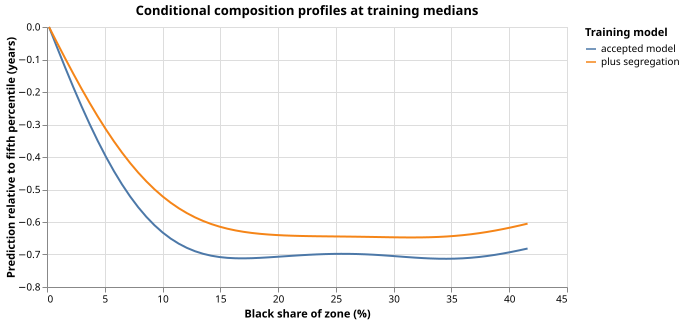

In [13]:
black_grid = np.linspace(train["cs_frac_black"].quantile(.05),
                         train["cs_frac_black"].quantile(.95), 60)
adjusted = mb.gamboost(
    f"{response} ~ {alternatives['add segregation']}", train,
    family=mb.Gaussian(), control=mb.boost_control(session.mstop, .3))
curves = []
for name, model in (("accepted model", session.model),
                    ("plus segregation", adjusted)):
    years = profile(model, "cs_frac_black", black_grid)
    curves.append(pl.DataFrame({"percent_black": black_grid,
                                "relative_years": years - years[0],
                                "model": name}))
profile_chart = alt.Chart(pl.concat(curves)).mark_line().encode(
    x=alt.X("percent_black:Q", title="Black share of zone (%)"),
    y=alt.Y("relative_years:Q", title="Prediction relative to fifth percentile (years)"),
    color=alt.Color("model:N", title="Training model"),
).properties(title="Conditional composition profiles at training medians",
             width=520, height=260)
display(profile_chart)

The segregation-adjusted profile is flatter over roughly 10–35% Black share,
and its shallow middle rise is reduced. Adding segregation nevertheless
changes new-state fold MSE by
{eval}`round(hypothesis_rows["add segregation"]["change"], 3)` years²
(paired SE {eval}`round(hypothesis_rows["add segregation"]["change se"], 3)`);
it does not clear the search rule. This is evidence of shared descriptive
signal, not an estimate of a latent cause. Both lines are conditional predictions for potentially
uncommon combinations of area characteristics.



## Final test-state prediction

The specification was chosen on training states before this point. The
hypothesis extension under "Targeted alternatives" does not adopt a different model.
`final_evaluate` freezes this fit (fixes every choice before test responses are read) and reads test responses once, reporting
MSE for zones in states excluded from fitting and model choice. The final evaluation depends only on the specification chosen above, so it can run directly after the first
prediction.

In [14]:
session.run("freeze")
final_result = session.run("final_evaluate", data=test)
print(f"Held-out states: {test['stateabbrv'].n_unique()}; "
      f"zones: {final_result.summary['n_test']}")
print(f"Final test MSE: {final_result.summary['score']:.3f} years²")

Held-out states: 9; zones: 118
Final test MSE: 1.359 years²


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(cur_smoke_q1), covariate cur_smoke_q1: 3 below 0.111111 and 1 above 0.5 (worst 0.29 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.29 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(


The test MSE is {eval}`round(final_result.summary['score'], 3)` years² on
{eval}`test.height` zones in {eval}`test['stateabbrv'].n_unique()` states.
One state split cannot show how much this procedure varies across other
training samples. The training-fold comparisons selected the formula and
are descriptive; the test score is the one independent prediction check in
this worked case.

## Search record and scope

The session state lists available actions, the fits charged to the budget,
fold identifiers and identifiers for earlier results. A JSON checkpoint can
resume the session with the same training data and native build. Because the
checkpoint omits fitted native objects, resuming requires a refit before
residual inspection or freezing. The final record shows which analyst-chosen
actions ran and whether each succeeded.

In [15]:
action_rows = [{"action": item.action, "status": item.status,
                "fit_charges": item.fit_charges,
                "evidence": item.evidence_id[:10]}
               for item in session.evidence]
display(table(
    pl.DataFrame(action_rows), title="Agent-directed action record",
    subtitle="Training actions and one final test evaluation; fit charges per action",
    stub="action", stubhead="Operation",
    notes=("Evidence prefixes identify the full records in session.checkpoint().",
           "A screening or hypothesis action is not a measured model comparison."),
))

GT(_tbl_data=shape: (12, 4)
┌────────────────┬────────────────┬─────────────┬────────────┐
│ action         ┆ status         ┆ fit_charges ┆ evidence   │
│ ---            ┆ ---            ┆ ---         ┆ ---        │
│ str            ┆ str            ┆ i64         ┆ str        │
╞════════════════╪════════════════╪═════════════╪════════════╡
│ classify       ┆ screening_only ┆ 0           ┆ afca88e895 │
│ set_spec       ┆ unmeasured     ┆ 0           ┆ 0ea4a8712d │
│ hypothesis     ┆ screening_only ┆ 0           ┆ cce601739f │
│ hypothesis     ┆ screening_only ┆ 0           ┆ 60c1abd192 │
│ hypothesis     ┆ screening_only ┆ 0           ┆ 489b88d111 │
│ …              ┆ …              ┆ …           ┆ …          │
│ tune           ┆ measured       ┆ 11          ┆ 2c84d723be │
│ term_report    ┆ measured       ┆ 25          ┆ 01f5ad5d4a │
│ compare        ┆ measured       ┆ 35          ┆ d02ebbcc64 │
│ freeze         ┆ unmeasured     ┆ 0           ┆ 1a8d2c2de6 │
│ final_evaluate ┆ measured       ┆ 0           ┆ e39e096311 │
└────────────────┴────────────────┴─────────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10bcca030>, _boxhead=Boxhead([ColInfo(var='action', type=<ColInfoTypeEnum.stub: 2>, column_label='action', column_align='left', column_width=None), ColInfo(var='status', type=<ColInfoTypeEnum.default: 1>, column_label='status', column_align='left', column_width=None), ColInfo(var='fit_charges', type=<ColInfoTypeEnum.default: 1>, column_label='fit_charges', column_align='right', column_width=None), ColInfo(var='evidence', type=<ColInfoTypeEnum.default: 1>, column_label='evidence', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x110fc81a0>, _spanners=Spanners([]), _heading=Heading(title='Agent-directed action record', subtitle='Training actions and one final test evaluation; fit charges per action', preheader=None), _stubhead='Operation', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x109f1d0d0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10c2f0e60>, _source_notes=['Evidence prefixes identify the full records in session.checkpoint().', 'A screening or hypothesis action is not a measured model comparison.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x110fcbb30>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x110fcb740>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='tabl

An analyst could next investigate whether smoking trends measured before
mortality, care access, disease burden and segregation histories support a
causal design. These columns alone cannot establish time order, exclude
unmeasured confounding or specify an intervention on racial composition.
The search supplies a predictive model and hypotheses for further study. The [methodology note](../methodology/search_decisions.ipynb)
explains why searching on the training folds does not turn their paired
standard errors into causal or confirmatory intervals.

### Extension: the broader scripted search

The 39-variable example is a deterministic scripted search, with
stability selection (refits on many half-samples, keeping terms selected in more than a cutoff share of them), multiple rounds and a recorded five-split investigation.
It is useful as a sensitivity study, but it does not choose its next diagnostic
or reason about variable roles. Its measured results are stored in `bench_cz_agent_search.json`, produced by
`benches/bench_cz_agent_search.py`. The
[hand-built descriptive study](cz_inequality.ipynb) covers the broader data.
The workflow in the main sections introduces the public actions; the recorded broader
search examines sensitivity to a larger set of candidate variables.